# CART Classification: Wine Cultivar Prediction

**Goal:** predict one of three wine cultivars from chemical measurements, using a Classification and Regression Tree (CART). We use scikit-learn's bundled Wine dataset: 178 observations, 13 numeric features, and three classes. It requires no download and provides a more useful evaluation exercise than the 14-row Tennis dataset.

**Workflow:** inspect data → stratified train/test split → full tree → pre-pruning → post-pruning → training-only model selection → held-out evaluation → interpretation and a new prediction.

CART classification uses **binary splits**, even for a three-class target. A split reduces Gini impurity, $G = 1 - \sum_k p_k^2$. Leaves predict the majority class; their class proportions provide probability estimates. Regression trees instead predict a numeric value, typically the leaf mean.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, log_loss,
    classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False,
                     'axes.spines.right': False})
np.set_printoptions(precision=4, suppress=True)

## 1. Load and inspect the dataset

Each row describes a wine sample using laboratory measurements. Class labels identify cultivars, not a quality ranking. We retain the dataset's `class_0`, `class_1`, and `class_2` names. Numeric inputs need neither categorical encoding nor feature scaling for a decision tree.

Source: the Wine dataset bundled with `sklearn.datasets.load_wine`; its description and provenance are available in `wine.DESCR`.

178 samples | 13 numeric features | 3 classes


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,class_0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,class_0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,class_0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


Missing values: 0
Duplicate rows: 0


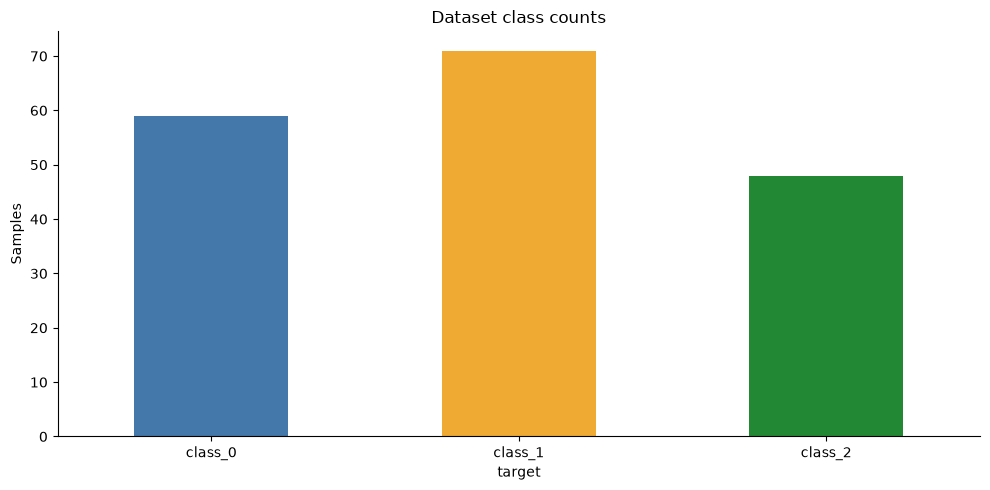

In [11]:
wine = load_wine(as_frame=True)
X = wine.data.copy()
y = wine.target.copy()
class_ids = np.unique(y)
class_names = wine.target_names.tolist()
class_lookup = dict(zip(class_ids, class_names))
df = X.assign(Cultivar=y.map(class_lookup))
print(f'{len(df)} samples | {X.shape[1]} numeric features | {y.nunique()} classes')
display(df.head(8))
display(X.describe().T.round(2))
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
assert not df.isna().any().any()
assert X.columns.is_unique

y.map(class_lookup).value_counts().sort_index().plot.bar(
    color=['#4477AA', '#EEAA33', '#228833'], rot=0, title='Dataset class counts'
)
plt.ylabel('Samples')
plt.tight_layout()
plt.show()

## 2. Reserve the test set before training

Hold out 25% of observations using a stratified split. Model selection uses only the training set and five stratified cross-validation folds. The test set is used once for the final comparison and diagnostics; we do not adjust hyperparameters after seeing its results.

We optimize **balanced accuracy**, the average recall across the three classes, so each class contributes equally. Ordinary accuracy counts all correctly classified samples equally.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print('Training samples:', len(X_train), '| Test samples:', len(X_test))
split_counts = pd.DataFrame({
    'Train': y_train.map(class_lookup).value_counts(),
    'Test': y_test.map(class_lookup).value_counts()
}).sort_index()
display(split_counts)
assert set(X_train.index).isdisjoint(X_test.index)

def show_tree(model, title, max_depth=None):
    plt.figure(figsize=(20, 10))
    plot_tree(model, feature_names=X.columns.tolist(),
              class_names=[class_lookup[c] for c in model.classes_],
              filled=True, rounded=True, precision=3, fontsize=8,
              max_depth=max_depth)
    plt.title(title)
    plt.tight_layout()
    plt.show()

Training samples: 133 | Test samples: 45


,Train,Test
target,,
class_0,44,15
class_1,53,18
class_2,36,12


## 3. Grow the full CART tree

With no depth or leaf-size restrictions, the tree can fit very specific training patterns. Inspect its depth, leaf count, training score, and validation score to see whether training performance carries over to unseen folds.

In the plot, `gini` measures class mixture, `samples` counts training rows at that node, and `value` gives class counts or proportions depending on the installed scikit-learn version. The left branch satisfies the displayed threshold; the right branch does not.

Depth: 4 | Leaves: 8
Training accuracy: 1.0
CV balanced accuracy: 0.904 ± 0.055


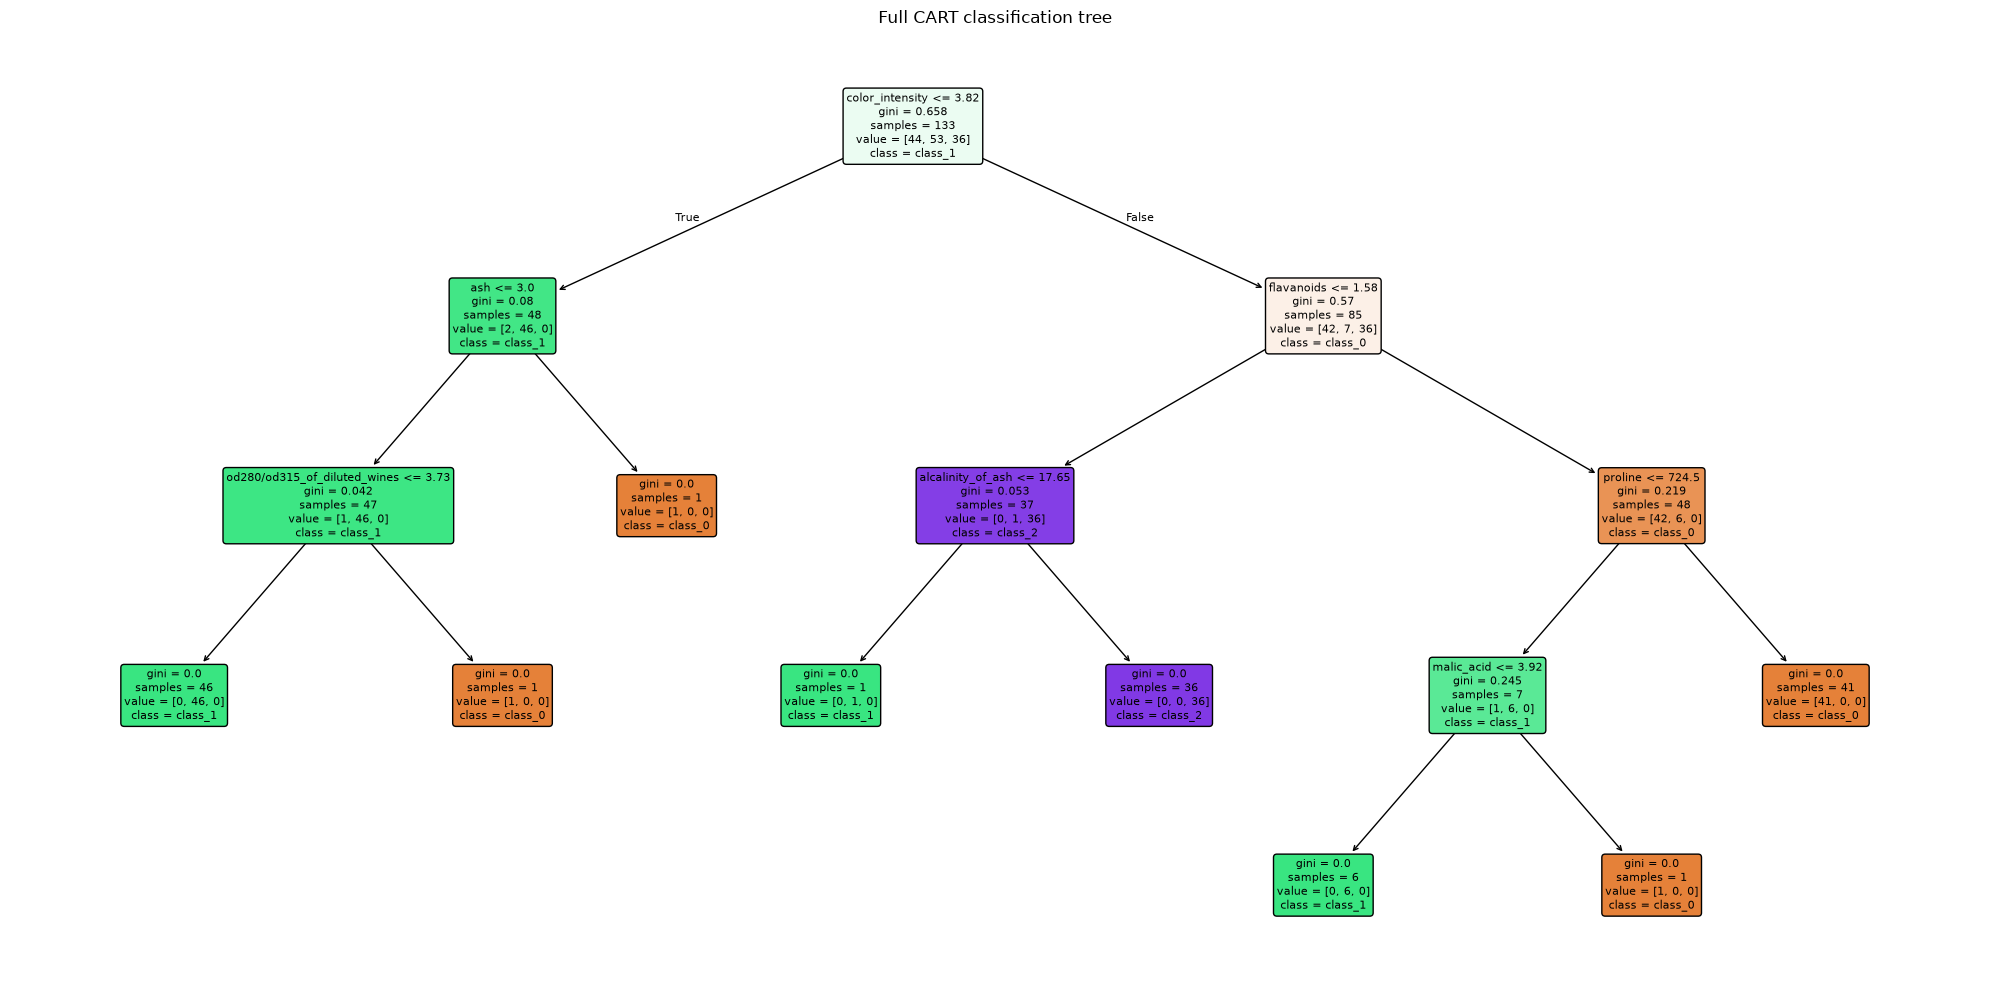

In [13]:
full_tree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_STATE)
full_tree.fit(X_train, y_train)
full_cv_scores = cross_val_score(full_tree, X_train, y_train, cv=cv, scoring='balanced_accuracy')
print('Depth:', full_tree.get_depth(), '| Leaves:', full_tree.get_n_leaves())
print('Training accuracy:', round(full_tree.score(X_train, y_train), 3))
print(f'CV balanced accuracy: {full_cv_scores.mean():.3f} ± {full_cv_scores.std():.3f}')
show_tree(full_tree, 'Full CART classification tree')

## 4. Pre-prune: restrict growth during training

Tune `max_depth` (maximum number of splits along a path) and `min_samples_leaf` (minimum training rows per leaf). Each candidate is evaluated on the same five training folds. Grid search refits the chosen candidate on all training rows.

The reported fold standard deviation describes variation across folds; it is not a confidence interval. The best tuning score can be optimistic because many candidates were compared.

Chosen pre-pruning parameters: {'max_depth': 3, 'min_samples_leaf': 2}
Best CV balanced accuracy: 0.918


,param_max_depth,param_min_samples_leaf,mean_train_score,mean_test_score,std_test_score
9,3,2,0.990,0.918,0.033
21,6,2,0.990,0.912,0.036
13,4,2,0.990,0.912,0.036
17,5,2,0.990,0.912,0.036
10,3,4,0.972,0.912,0.015
22,6,4,0.972,0.912,0.015
18,5,4,0.972,0.912,0.015
14,4,4,0.972,0.912,0.015


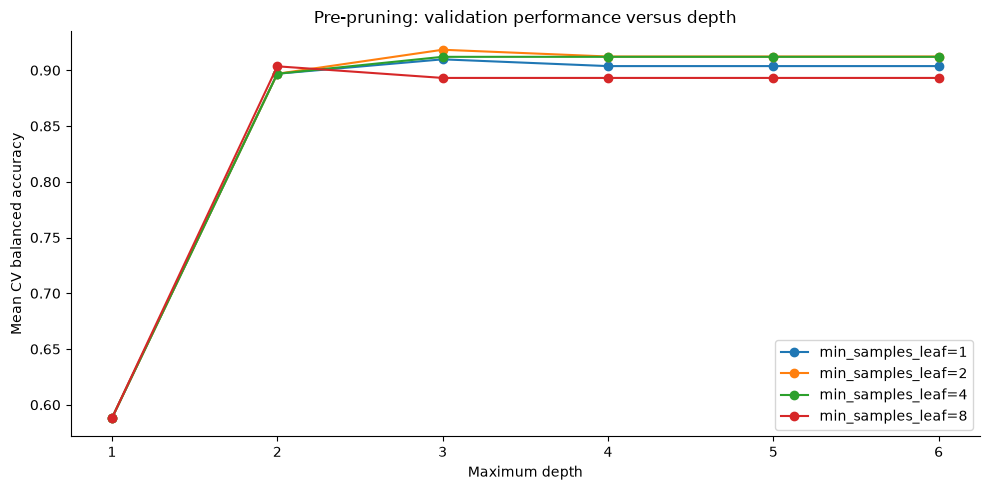

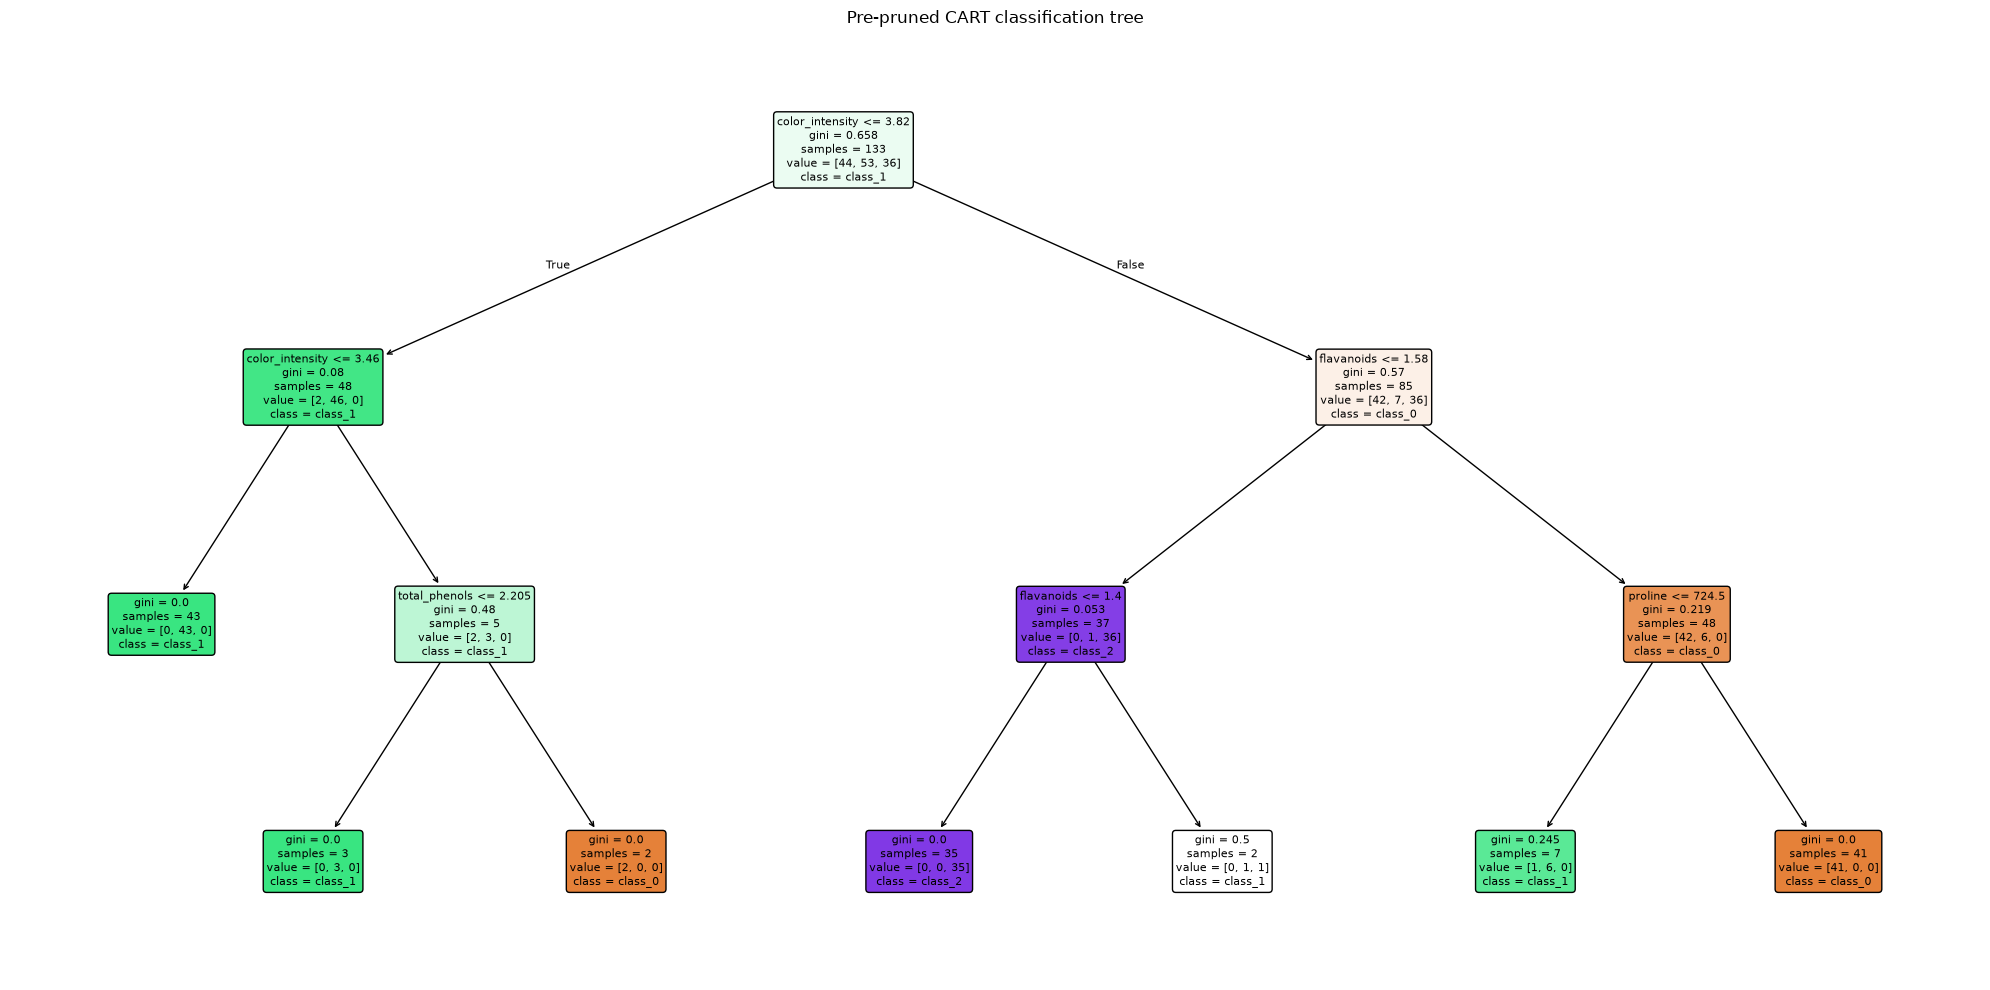

In [14]:
pre_search = GridSearchCV(
    DecisionTreeClassifier(criterion='gini', random_state=RANDOM_STATE),
    param_grid={'max_depth': [1, 2, 3, 4, 5, 6], 'min_samples_leaf': [1, 2, 4, 8]},
    scoring='balanced_accuracy', cv=cv, return_train_score=True, error_score='raise'
)
pre_search.fit(X_train, y_train)
pruned_tree = pre_search.best_estimator_
print('Chosen pre-pruning parameters:', pre_search.best_params_)
print(f'Best CV balanced accuracy: {pre_search.best_score_:.3f}')
pre_results = pd.DataFrame(pre_search.cv_results_)
display(pre_results[['param_max_depth', 'param_min_samples_leaf',
                     'mean_train_score', 'mean_test_score', 'std_test_score']]
        .sort_values('mean_test_score', ascending=False).head(8).round(3))

for leaf_size, group in pre_results.groupby('param_min_samples_leaf'):
    group = group.sort_values('param_max_depth')
    plt.plot(group['param_max_depth'].astype(int), group['mean_test_score'],
             marker='o', label=f'min_samples_leaf={leaf_size}')
plt.xlabel('Maximum depth')
plt.ylabel('Mean CV balanced accuracy')
plt.title('Pre-pruning: validation performance versus depth')
plt.legend()
plt.tight_layout()
plt.show()
show_tree(pruned_tree, 'Pre-pruned CART classification tree')

## 5. Post-prune: cost-complexity pruning

Minimal cost-complexity pruning balances weighted leaf impurity against `ccp_alpha × number of leaves`. Increasing alpha favors smaller trees. Alpha 0 allows the full tree, while a sufficiently large alpha leaves only the root.

The full-training pruning path below illustrates this tradeoff. Hyperparameter selection uses a **fixed alpha grid**, rather than a grid derived from all training labels before cross-validation. Test observations never influence alpha selection.

Chosen alpha: 0.018478497974222907
Best CV balanced accuracy: 0.919
Depth: 3 | Leaves: 4


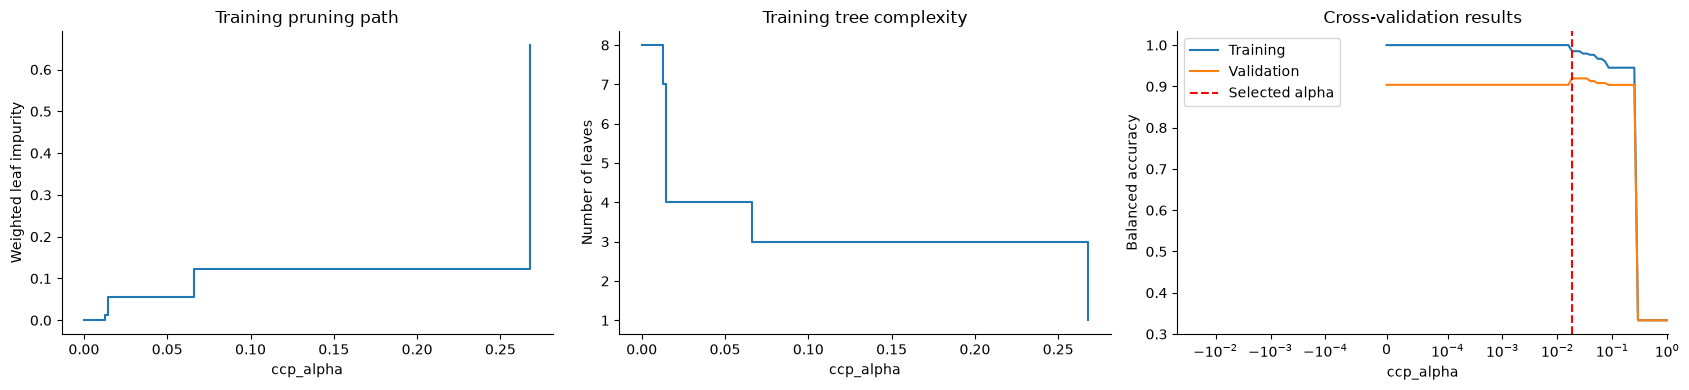

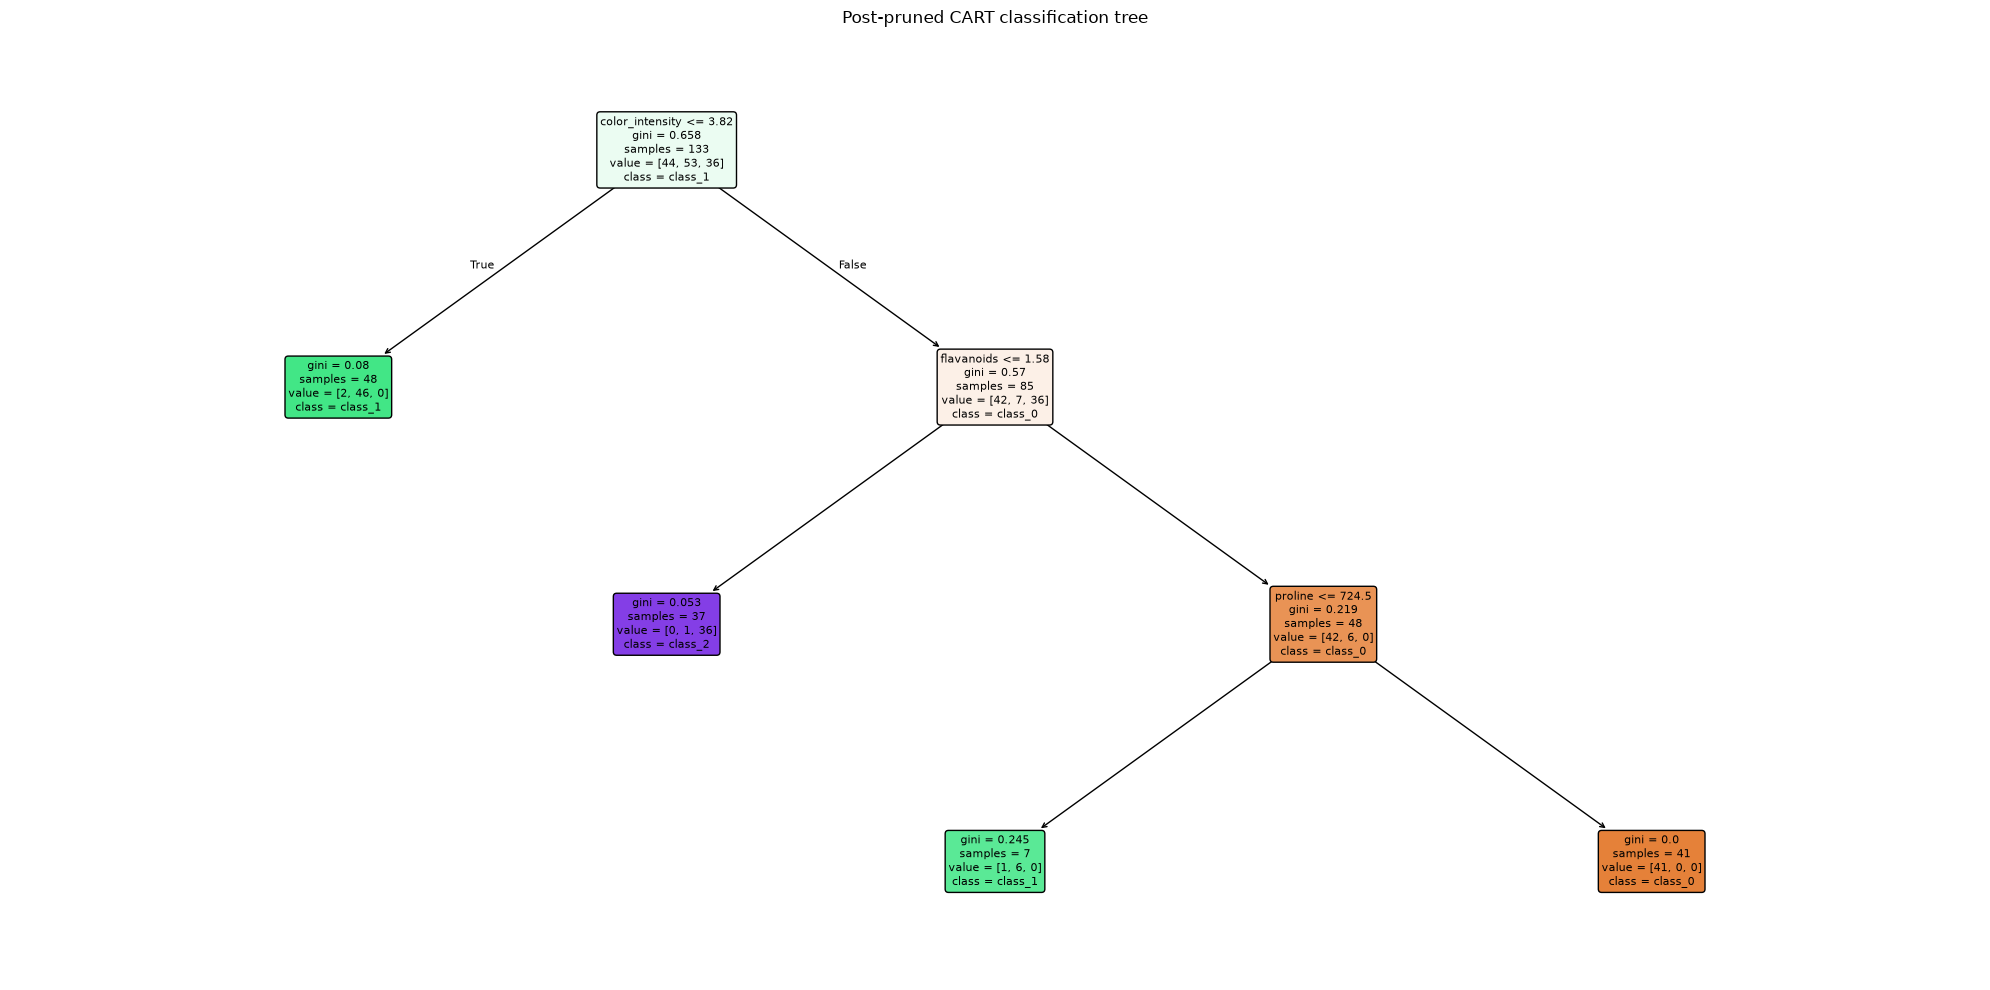

In [15]:
path = full_tree.cost_complexity_pruning_path(X_train, y_train)
alpha_grid = np.r_[0.0, np.logspace(-4, 0, 61)]
post_search = GridSearchCV(
    DecisionTreeClassifier(criterion='gini', random_state=RANDOM_STATE),
    param_grid={'ccp_alpha': alpha_grid}, scoring='balanced_accuracy',
    cv=cv, return_train_score=True, error_score='raise'
)
post_search.fit(X_train, y_train)
post_pruned_tree = post_search.best_estimator_
print('Chosen alpha:', post_search.best_params_['ccp_alpha'])
print(f'Best CV balanced accuracy: {post_search.best_score_:.3f}')
print('Depth:', post_pruned_tree.get_depth(), '| Leaves:', post_pruned_tree.get_n_leaves())

# Full-training fits below illustrate complexity only; they do not select alpha.
path_leaves = [DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=float(a))
               .fit(X_train, y_train).get_n_leaves() for a in path.ccp_alphas]
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].step(path.ccp_alphas, path.impurities, where='post')
axes[0].set(xlabel='ccp_alpha', ylabel='Weighted leaf impurity', title='Training pruning path')
axes[1].step(path.ccp_alphas, path_leaves, where='post')
axes[1].set(xlabel='ccp_alpha', ylabel='Number of leaves', title='Training tree complexity')
for score, label in [('mean_train_score', 'Training'), ('mean_test_score', 'Validation')]:
    axes[2].plot(alpha_grid, post_search.cv_results_[score], label=label)
axes[2].axvline(post_search.best_params_['ccp_alpha'], color='red', linestyle='--', label='Selected alpha')
axes[2].set_xscale('symlog', linthresh=0.0001)
axes[2].set(xlabel='ccp_alpha', ylabel='Balanced accuracy', title='Cross-validation results')
axes[2].legend()
plt.tight_layout()
plt.show()
show_tree(post_pruned_tree, 'Post-pruned CART classification tree')

## 6. Select the final model using training data only

Compare the full tree and the best candidates from both pruning searches. Choose the highest mean CV balanced accuracy; exact ties favor fewer leaves, then lower depth. Keeping the full tree eligible avoids assuming that pruning must improve results.

A majority-class baseline helps interpret the scores. Cross-validation results guide selection; the held-out test results in the next section estimate the selected model's performance.

In [16]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
baseline_cv = cross_val_score(baseline, X_train, y_train, cv=cv, scoring='balanced_accuracy')
models = {'Majority baseline': baseline, 'Full Tree': full_tree,
          'Pre-Pruned Tree': pruned_tree, 'Post-Pruned Tree': post_pruned_tree}
cv_means = {'Majority baseline': baseline_cv.mean(), 'Full Tree': full_cv_scores.mean(),
            'Pre-Pruned Tree': pre_search.best_score_, 'Post-Pruned Tree': post_search.best_score_}
cv_stds = {'Majority baseline': baseline_cv.std(), 'Full Tree': full_cv_scores.std(),
           'Pre-Pruned Tree': pre_search.cv_results_['std_test_score'][pre_search.best_index_],
           'Post-Pruned Tree': post_search.cv_results_['std_test_score'][post_search.best_index_]}
best_model_name = max(
    ['Full Tree', 'Pre-Pruned Tree', 'Post-Pruned Tree'],
    key=lambda name: (cv_means[name], -models[name].get_n_leaves(), -models[name].get_depth())
)
best_model = models[best_model_name]
selection = pd.DataFrame({'CV balanced accuracy': cv_means, 'Fold std': cv_stds})
display(selection.round(3))
print('Selected model:', best_model_name)
print('Selected parameters:', {k: best_model.get_params()[k]
                              for k in ['criterion', 'max_depth', 'min_samples_leaf', 'ccp_alpha']})

,CV balanced accuracy,Fold std
Majority baseline,0.333,0.000
Full Tree,0.904,0.055
Pre-Pruned Tree,0.918,0.033
Post-Pruned Tree,0.919,0.038


Selected model: Post-Pruned Tree
Selected parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'ccp_alpha': np.float64(0.018478497974222907)}


## 7. Evaluate the frozen models on held-out data

**Accuracy:** fraction correct. **Balanced accuracy:** mean per-class recall. **Macro F1:** mean of each class's precision/recall balance. Higher values are better for all three. **Log loss** evaluates predicted probabilities; lower is better and confident wrong predictions are penalized heavily. Tree leaf frequencies can be overconfident, so good classification accuracy does not guarantee good probabilities.

All models are shown for educational comparison. The selected model remains the one chosen above, regardless of test rankings.

,Depth,Leaves,CV balanced accuracy,Train balanced accuracy,Test accuracy,Test balanced accuracy,Test macro F1,Test log loss
Model,,,,,,,,
Majority baseline,NaN,NaN,0.333,0.333,0.400,0.333,0.190,21.626
Full Tree,4.0,8.0,0.904,1.000,0.956,0.950,0.956,1.602
Pre-Pruned Tree,3.0,7.0,0.918,0.983,1.000,1.000,1.000,0.014
Post-Pruned Tree,3.0,4.0,0.919,0.971,0.956,0.956,0.959,0.175


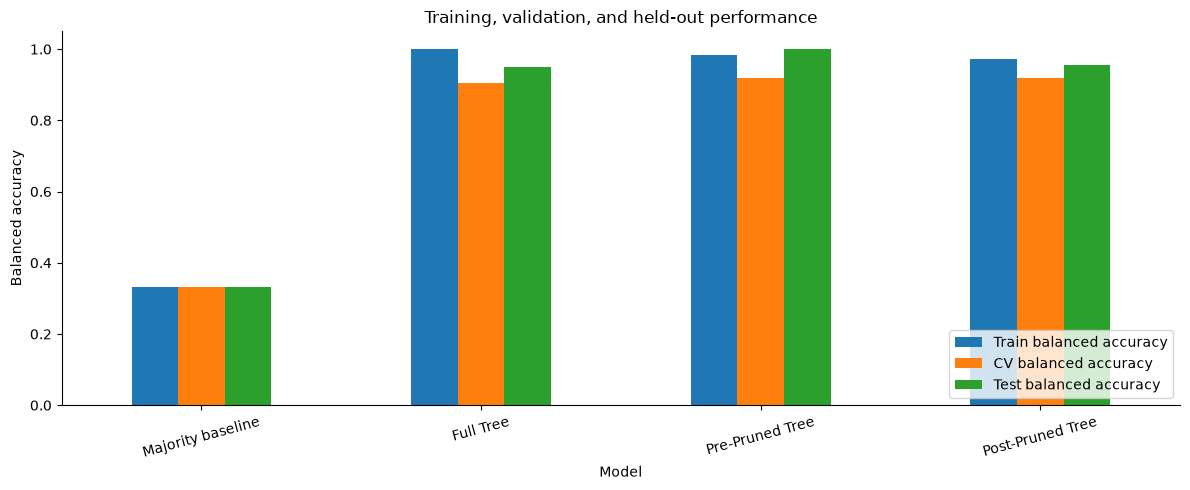

In [17]:
rows = []
for name, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    rows.append({
        'Model': name,
        'Depth': model.get_depth() if isinstance(model, DecisionTreeClassifier) else np.nan,
        'Leaves': model.get_n_leaves() if isinstance(model, DecisionTreeClassifier) else np.nan,
        'CV balanced accuracy': cv_means[name],
        'Train balanced accuracy': balanced_accuracy_score(y_train, train_pred),
        'Test accuracy': accuracy_score(y_test, test_pred),
        'Test balanced accuracy': balanced_accuracy_score(y_test, test_pred),
        'Test macro F1': f1_score(y_test, test_pred, average='macro', zero_division=0),
        'Test log loss': log_loss(y_test, model.predict_proba(X_test), labels=model.classes_)
    })
comparison = pd.DataFrame(rows).set_index('Model')
display(comparison.round(3))
comparison[['Train balanced accuracy', 'CV balanced accuracy', 'Test balanced accuracy']].plot.bar(
    figsize=(12, 5), rot=15, ylim=(0, 1.05), title='Training, validation, and held-out performance'
)
plt.ylabel('Balanced accuracy')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Classification report: Post-Pruned Tree
              precision    recall  f1-score   support

     class_0       1.00      0.87      0.93        15
     class_1       0.90      1.00      0.95        18
     class_2       1.00      1.00      1.00        12

    accuracy                           0.96        45
   macro avg       0.97      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



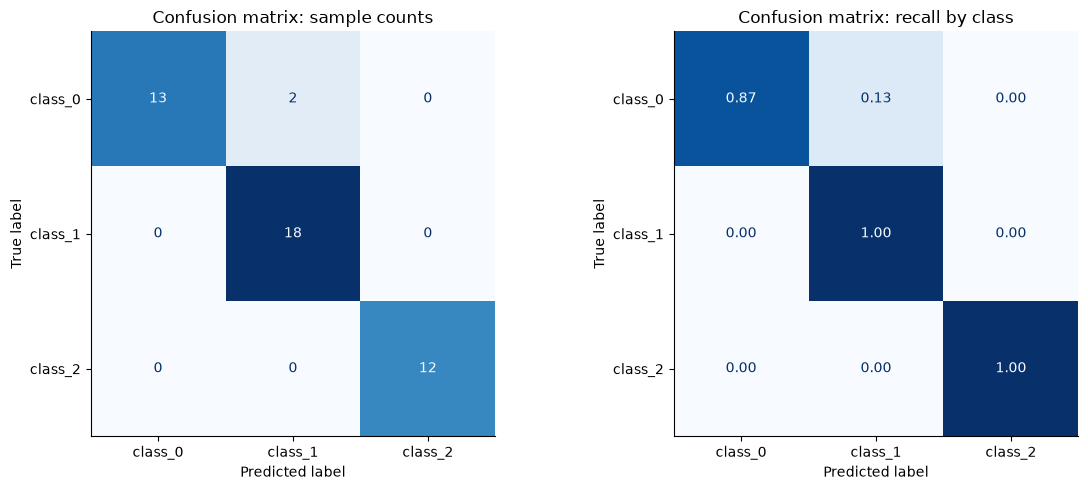

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Actual,Predicted,Largest leaf probability,Correct
35,13.48,1.81,2.41,20.5,100.0,2.70,2.98,0.26,1.86,5.10,1.04,3.47,920.0,class_0,class_0,1.000,True
93,12.29,2.83,2.22,18.0,88.0,2.45,2.25,0.25,1.99,2.15,1.15,3.30,290.0,class_1,class_1,0.958,True
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,class_0,class_0,1.000,True
28,13.87,1.90,2.80,19.4,107.0,2.95,2.97,0.37,1.76,4.50,1.25,3.40,915.0,class_0,class_0,1.000,True
87,11.65,1.67,2.62,26.0,88.0,1.92,1.61,0.40,1.34,2.60,1.36,3.21,562.0,class_1,class_1,0.958,True
42,13.88,1.89,2.59,15.0,101.0,3.25,3.56,0.17,1.70,5.43,0.88,3.56,1095.0,class_0,class_0,1.000,True
18,14.19,1.59,2.48,16.5,108.0,3.30,3.93,0.32,1.86,8.70,1.23,2.82,1680.0,class_0,class_0,1.000,True
60,12.33,1.10,2.28,16.0,101.0,2.05,1.09,0.63,0.41,3.27,1.25,1.67,680.0,class_1,class_1,0.958,True
98,12.37,1.07,2.10,18.5,88.0,3.52,3.75,0.24,1.95,4.50,1.04,2.77,660.0,class_1,class_1,0.857,True
130,12.86,1.35,2.32,18.0,122.0,1.51,1.25,0.21,0.94,4.10,0.76,1.29,630.0,class_2,class_2,0.973,True


Misclassified test examples: 2


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Actual,Predicted,Largest leaf probability,Correct
22,13.71,1.86,2.36,16.6,101.0,2.61,2.88,0.27,1.69,3.8,1.11,4.00,1035.0,class_0,class_1,0.958,False
38,13.07,1.50,2.10,15.5,98.0,2.40,2.64,0.28,1.37,3.7,1.18,2.69,1020.0,class_0,class_1,0.958,False


In [18]:
predictions = best_model.predict(X_test)
probabilities = best_model.predict_proba(X_test)
print(f'Classification report: {best_model_name}')
print(classification_report(y_test, predictions, labels=class_ids,
                            target_names=class_names, zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=class_ids,
    display_labels=class_names, cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title('Confusion matrix: sample counts')
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=class_ids,
    display_labels=class_names, normalize='true', values_format='.2f',
    cmap='Blues', ax=axes[1], colorbar=False)
axes[1].set_title('Confusion matrix: recall by class')
plt.tight_layout()
plt.show()

results = X_test.copy()
results['Actual'] = y_test.map(class_lookup)
results['Predicted'] = pd.Series(predictions, index=X_test.index).map(class_lookup)
results['Largest leaf probability'] = probabilities.max(axis=1)
results['Correct'] = predictions == y_test.to_numpy()
display(results.head(10).round(3))
print('Misclassified test examples:', int((~results['Correct']).sum()))
display(results.loc[~results['Correct']].round(3))

## 8. Interpret the selected tree

The root split below demonstrates the CART calculation: parent Gini minus the child impurities weighted by their sample counts. It measures local impurity reduction, not predictive accuracy.

Impurity importance sums reductions throughout the fitted tree and can favor features with many possible thresholds. Permutation importance measures the drop in held-out balanced accuracy when one feature is shuffled. Correlated features can share or mask importance. These diagnostics are interpreted after model selection and are not used to retune it. Error bars show variation over repeated shuffles, not confidence intervals.

Root split: color_intensity <= 3.820
Parent Gini: 0.6585
Weighted child Gini: 0.3929
Gini decrease: 0.2656


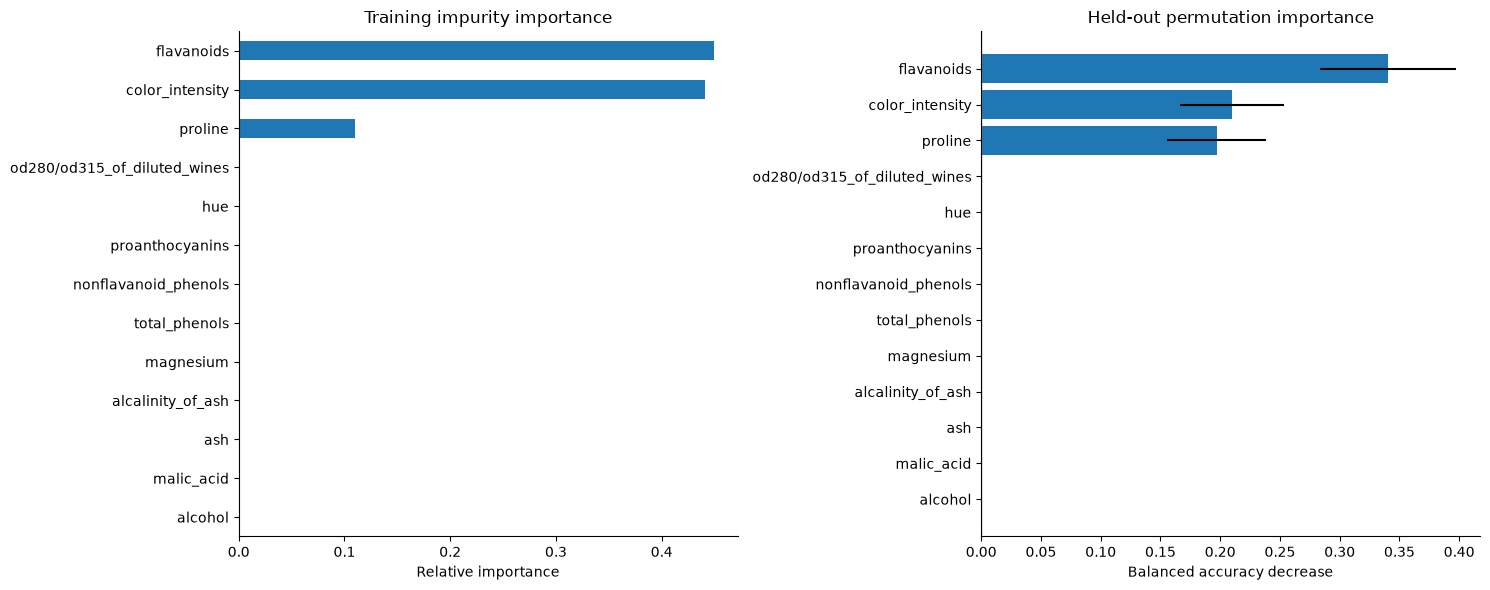

Selected tree rules:
|--- color_intensity <= 3.820
|   |--- class: 1
|--- color_intensity >  3.820
|   |--- flavanoids <= 1.580
|   |   |--- class: 2
|   |--- flavanoids >  1.580
|   |   |--- proline <= 724.500
|   |   |   |--- class: 1
|   |   |--- proline >  724.500
|   |   |   |--- class: 0



In [19]:
structure = best_model.tree_
if structure.children_left[0] != -1:
    left, right = structure.children_left[0], structure.children_right[0]
    counts = structure.weighted_n_node_samples
    weighted_children = (counts[left] * structure.impurity[left] +
                         counts[right] * structure.impurity[right]) / counts[0]
    print(f'Root split: {X.columns[structure.feature[0]]} <= {structure.threshold[0]:.3f}')
    print(f'Parent Gini: {structure.impurity[0]:.4f}')
    print(f'Weighted child Gini: {weighted_children:.4f}')
    print(f'Gini decrease: {structure.impurity[0] - weighted_children:.4f}')
else:
    print('The selected tree is a single leaf; there is no root split.')

impurity = pd.Series(best_model.feature_importances_, index=X.columns).sort_values()
permutation = permutation_importance(best_model, X_test, y_test,
    scoring='balanced_accuracy', n_repeats=30, random_state=RANDOM_STATE)
perm_table = pd.DataFrame({'Mean score decrease': permutation.importances_mean,
                           'Shuffle std': permutation.importances_std}, index=X.columns)
perm_table = perm_table.sort_values('Mean score decrease')
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
impurity.plot.barh(ax=axes[0], title='Training impurity importance')
axes[0].set_xlabel('Relative importance')
axes[1].barh(perm_table.index, perm_table['Mean score decrease'], xerr=perm_table['Shuffle std'])
axes[1].axvline(0, color='gray', linewidth=1)
axes[1].set(title='Held-out permutation importance', xlabel='Balanced accuracy decrease')
plt.tight_layout()
plt.show()
print('Selected tree rules:')
print(export_text(best_model, feature_names=X.columns.tolist(), decimals=3))

## 9. Predict a hypothetical new sample

Create a complete feature row using **training medians**, then supply two example measurements. This is an illustrative synthetic sample with no known true class, not an additional test observation. In practice, replace all fields with measurements collected in the same units as the training data.

The probability vector is the class distribution in the reached leaf. It should not be interpreted as calibrated confidence.

In [20]:
new_sample = X_train.median().to_frame().T
new_sample.index = ['Hypothetical sample']
new_sample.loc[:, 'alcohol'] = 13.2
new_sample.loc[:, 'proline'] = 850.0
new_sample = new_sample[X.columns]
display(new_sample.round(3))
new_prediction = best_model.predict(new_sample)[0]
print('Predicted cultivar:', class_lookup[new_prediction])
display(pd.DataFrame(best_model.predict_proba(new_sample),
                     columns=[class_lookup[c] for c in best_model.classes_], index=new_sample.index))
leaf_id = best_model.apply(new_sample)[0]
print('Reached leaf:', leaf_id)
print('Training samples in this leaf:', best_model.tree_.n_node_samples[leaf_id])

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
Hypothetical sample,13.2,1.81,2.36,20.0,98.0,2.4,2.14,0.34,1.57,4.68,0.96,2.78,850.0


Predicted cultivar: class_0


,class_0,class_1,class_2
Hypothetical sample,1.0,0.0,0.0


Reached leaf: 6
Training samples in this leaf: 41


## 10. Conclusions from this run

The following summary is generated from the actual results, so it stays consistent when the notebook is rerun.

In [21]:
selected_results = comparison.loc[best_model_name]
print(f'Selected by training CV: {best_model_name}')
print(f'Tree complexity: depth {best_model.get_depth()}, {best_model.get_n_leaves()} leaves')
print(f'CV balanced accuracy: {cv_means[best_model_name]:.1%}')
print(f'Test accuracy: {selected_results["Test accuracy"]:.1%}')
print(f'Test balanced accuracy: {selected_results["Test balanced accuracy"]:.1%}')
print(f'Test macro F1: {selected_results["Test macro F1"]:.3f}')
print(f'Test mistakes: {(predictions != y_test.to_numpy()).sum()} / {len(y_test)}')
print(f'One test prediction changes ordinary accuracy by {100 / len(y_test):.2f} percentage points.')

# Basic consistency checks for the saved workflow.
assert len(predictions) == len(y_test)
assert np.allclose(probabilities.sum(axis=1), 1)
assert set(predictions).issubset(set(class_ids))
assert set(best_model.feature_names_in_) == set(X.columns)
print('Workflow checks passed.')

Selected by training CV: Post-Pruned Tree
Tree complexity: depth 3, 4 leaves
CV balanced accuracy: 91.9%
Test accuracy: 95.6%
Test balanced accuracy: 95.6%
Test macro F1: 0.959
Test mistakes: 2 / 45
One test prediction changes ordinary accuracy by 2.22 percentage points.
Workflow checks passed.


### Key takeaways

- CART uses binary threshold splits for this multiclass problem; it does not require one tree per class.
- Full trees can overfit. Pre-pruning constrains growth, while cost-complexity post-pruning removes complexity. Either can help, but improvement is not guaranteed.
- Splitting before training and keeping hyperparameter selection within training cross-validation prevents test feedback from driving the model choice.
- This dataset is still small. A single held-out split is an estimate, not a guarantee of performance on wines from other sources. Nested cross-validation or additional external data would support stronger claims.
- Feature importance is model-specific and does not establish causation. Leaf class frequencies are not automatically calibrated probabilities.
- This classification workflow parallels the regression notebook: replace numeric-price predictions and MAE/RMSE with class predictions and classification metrics.